In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC  # Hoặc LinearSVC nếu data lớn
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from scipy.sparse import hstack  # Để concat sparse và dense nếu cần

In [23]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
import pandas as pd

# Thay bằng link CSV thật của anh (phải là link công khai, trực tiếp đến file CSV)
url = '/content/drive/MyDrive/Bert/Data/clean_hochinhminh_khanhhoa_lamdong_binhdinh.csv' # Ví dụ: 'https://raw.githubusercontent.com/cs109/2014_data/master/countries.csv'

# Đọc file CSV từ URL
df = pd.read_csv(url)

# In ra 5 dòng đầu tiên
print(df.head(5))

   stt                hotel_name    country province_raw review_name  score  \
0    1    TTR Skypool View Hotel  Việt Nam       Đà Lạt        (k17   10.0   
1    2           Prime New Hotel  Việt Nam    Nha Trang         (mr    8.0   
2    3  The MCR Luxury Nha Trang  Việt Nam    Nha Trang        ,như   10.0   
3    4  Lavender Nha Trang Hotel  Việt Nam    Nha Trang        -dhn   10.0   
4    5      NAMI HOTEL Nha Trang  Việt Nam    Nha Trang        . pi    7.0   

   hotel_avg_score  deviation stay_duration  \
0              7.7        2.3         1 đêm   
1              7.8        0.2         3 đêm   
2              6.9        3.1         1 đêm   
3              8.9        1.1         1 đêm   
4              7.3       -0.3         6 đêm   

                                room_type  ...  \
0               Phòng Deluxe Giường Đôi  ...   
1    Suite Có Giường Cỡ King Nhìn Ra Biển  ...   
2    Phòng Deluxe Giường Đôi/2 Giường Đơn  ...   
3  Phòng Superior Giường Đôi Với Cửa Sổ 

In [25]:
df['review_info'] = df[['room_type_id', 'stay_duration_id', 'group_type_id']].values.tolist()
useful_columns = [
    'final',          # text chính để embed
    'hotel_info',
    'review_info',
    'score',
   # string list 7 số (sẽ convert sau)
    # thêm các cột khác bạn thấy quan trọng
]
df = df[useful_columns]
print(df.head(5))

                                               final  \
0  đánh giá: xuất_sắc ưu điểm: tốt về chất_lượng ...   
1  đánh giá: tiếc là đi vào ngày trời âm_u biển đ...   
2  đánh giá: xuất_sắc ưu điểm: phòng_ốc sạch_sẽ t...   
3  đánh giá: xuất_sắc ưu điểm: phòng sạch_sẽ gần ...   
4  đánh giá: hài_lòng ưu điểm: đối_diện biển rất ...   

                            hotel_info   review_info  score  
0  [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]   [408, 1, 3]   10.0  
1  [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]  [1205, 3, 0]    8.0  
2  [7.8, 6.6, 7.1, 5.5, 7.3, 6.7, 6.9]   [638, 1, 0]   10.0  
3  [9.2, 8.9, 9.1, 9.2, 9.3, 9.1, 9.2]   [985, 1, 0]   10.0  
4  [8.0, 7.6, 7.5, 7.7, 8.1, 8.7, 9.2]   [512, 6, 0]    7.0  


In [26]:
df.loc[:, 'label'] = df['score'].astype(int)
X = df['final']
y = df['label']

In [27]:
from sklearn.model_selection import train_test_split

# Giả sử docs = df['final'] và labels = df['label']
docs = df['final']
labels = df['score'].astype(int)

# Bước 1: Tách tập Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    docs, labels, test_size=0.2, random_state=42
)

# Bước 2: Tách tập Validation từ tập Train hiện tại (15% của 80% còn lại)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42
)

# Kiểm tra quân số các tập
print(f"--- KẾT QUẢ CHIA DỮ LIỆU ---")
print(f"Tổng mẫu: {len(docs)}")
print(f"Tập Train (68%): {len(X_train)} mẫu")
print(f"Tập Validation (12%): {len(X_val)} mẫu")
print(f"Tập Test (20%): {len(X_test)} mẫu")

--- KẾT QUẢ CHIA DỮ LIỆU ---
Tổng mẫu: 41136
Tập Train (68%): 27971 mẫu
Tập Validation (12%): 4937 mẫu
Tập Test (20%): 8228 mẫu


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 3. Định nghĩa Pipeline
# TfidfVectorizer: Chuyển văn bản thành vector số
# LogisticRegression: mô hình thay thế cho SVC
model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=5000)),
    ('lr', LogisticRegression(
        solver='lbfgs',              # hoặc 'saga' nếu dữ liệu rất lớn
        max_iter=1000,               # tăng nếu thấy chưa hội tụ
        C=1.0,                       # tham số điều chuẩn (inverse của regularization strength)
        class_weight='balanced',     # giữ nguyên để xử lý imbalance
        random_state=42,
        n_jobs=-1                    # dùng tất cả core (nếu solver hỗ trợ)
    ))
])

In [29]:
best_score = 0
best_C = 1

# Thử các giá trị C phổ biến (càng lớn C càng ít regularization → dễ overfit hơn)
for c_param in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]:
    # Cập nhật tham số C cho LogisticRegression
    model_pipeline.set_params(lr__C=c_param)
    model_pipeline.fit(X_train, y_train)

    # Đánh giá trên tập Validation
    val_score = model_pipeline.score(X_val, y_val)
    print(f"C = {c_param:.2f} => Validation Accuracy: {val_score:.4f}")

    if val_score > best_score:
        best_score = val_score
        best_C = c_param

print(f"---")
print(f"Tham số tốt nhất tìm được: C = {best_C:.2f}")

# Cuối cùng fit lại với C tốt nhất và đánh giá trên Test
model_pipeline.set_params(lr__C=best_C)
model_pipeline.fit(X_train, y_train)  # Có thể concat X_train + X_val để tăng data

print(f"Final Test Accuracy: {model_pipeline.score(X_test, y_test):.4f}")

C = 0.01 => Validation Accuracy: 0.7819
C = 0.10 => Validation Accuracy: 0.7863
C = 0.50 => Validation Accuracy: 0.7900
C = 1.00 => Validation Accuracy: 0.7893
C = 2.00 => Validation Accuracy: 0.7889
C = 5.00 => Validation Accuracy: 0.7829
C = 10.00 => Validation Accuracy: 0.7758
C = 50.00 => Validation Accuracy: 0.7632
---
Tham số tốt nhất tìm được: C = 0.50
Final Test Accuracy: 0.7713


In [30]:
y_pred = model_pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           5       0.53      0.76      0.62       194
           6       0.49      0.62      0.55       212
           7       0.40      0.72      0.51       483
           8       0.66      0.64      0.65      1107
           9       0.75      0.65      0.70      1712
          10       0.92      0.86      0.89      4520

    accuracy                           0.77      8228
   macro avg       0.63      0.71      0.65      8228
weighted avg       0.80      0.77      0.78      8228



In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch
import textwrap   # để in đẹp hơn nếu cần

# ----------------------------------------------------------------------
# Đảm bảo y_test và y_pred ở dạng numpy array (phổ biến nhất)
# ----------------------------------------------------------------------
if isinstance(y_test, torch.Tensor):
    y_test_np    = y_test.cpu().numpy()
else:
    y_test_np    = np.asarray(y_test)

if isinstance(y_pred, torch.Tensor):
    y_pred_np    = y_pred.cpu().numpy()
else:
    y_pred_np    = np.asarray(y_pred)

# Nếu là multi-class và y_pred là probability → lấy argmax
if len(y_pred_np.shape) > 1 and y_pred_np.shape[1] > 1:
    y_pred_np = np.argmax(y_pred_np, axis=1)

# ----------------------------------------------------------------------
# Tính các metric cơ bản
# ----------------------------------------------------------------------
accuracy = accuracy_score(y_test_np, y_pred_np)

# In header
print("\n" + "="*80)
print("              MODEL EVALUATION ON TEST SET")
print("="*80)

# Accuracy chi tiết
print(f"\nOverall Accuracy:")
print(f"  • {accuracy:.4f}  ({accuracy*100:.2f}%)")
print("-"*60)

# Classification Report (chi tiết, 4 chữ số thập phân)
print("\nClassification Report:")
print(classification_report(
    y_test_np,
    y_pred_np,
    digits=4,
    zero_division=0,
    target_names=[str(c) for c in model_pipeline.classes_]   # nếu có class names đẹp
    # target_names = ['Negative', 'Positive']  # → bạn có thể hard-code tên lớp nếu muốn
))

# ----------------------------------------------------------------------
# Confusion Matrix - cả dạng số lượng và dạng chuẩn hóa (%)
# ----------------------------------------------------------------------
cm = confusion_matrix(y_test_np, y_pred_np)

print("\nConfusion Matrix (Raw counts):")
print(cm)

# Chuẩn hóa theo hàng (precision-oriented: tỷ lệ dự đoán đúng trong mỗi lớp thật)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)  # tránh NaN nếu có lớp không có mẫu

# ----------------------------------------------------------------------
# Một số metric tổng hợp bổ sung (macro / weighted)
# ----------------------------------------------------------------------
print("\nSummary Metrics:")
print(f"  Macro    Avg Precision : {precision_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg Recall    : {recall_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg F1-score  : {f1_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Weighted Avg F1-score : {f1_score(y_test_np, y_pred_np, average='weighted', zero_division=0):.4f}")

# Kết thúc đẹp
# ----------------------------------------------------------------------
torch.cuda.empty_cache() if torch.cuda.is_available() else None

print("\n" + "="*80)
print(f"HOÀN TẤT ĐÁNH GIÁ!  •  Accuracy = {accuracy*100:.2f}%")
print("="*80 + "\n")


              MODEL EVALUATION ON TEST SET

Overall Accuracy:
  • 0.7713  (77.13%)
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           5     0.5307    0.7577    0.6242       194
           6     0.4943    0.6179    0.5493       212
           7     0.4007    0.7184    0.5145       483
           8     0.6599    0.6450    0.6524      1107
           9     0.7488    0.6495    0.6957      1712
          10     0.9158    0.8617    0.8880      4520

    accuracy                         0.7713      8228
   macro avg     0.6250    0.7084    0.6540      8228
weighted avg     0.7965    0.7713    0.7794      8228


Confusion Matrix (Raw counts):
[[ 147   15   26    3    0    3]
 [  36  131   38    3    1    3]
 [  39   38  347   33   12   14]
 [  24   34  165  714   98   72]
 [  11   28  143  152 1112  266]
 [  20   19  147  177  262 3895]]

Summary Metrics:
  Macro    Avg Precision : 0.6250
  Mac

In [32]:
import joblib
import os
from datetime import datetime

save_dir = '/content/drive/MyDrive/Bert/Model/tf-idf-lr'
os.makedirs(save_dir, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
base_name = f'sentiment_model_{timestamp}'

# Lưu riêng vectorizer
vectorizer_filename = os.path.join(save_dir, f'{base_name}_tfidf_vectorizer.pkl')
joblib.dump(model_pipeline.named_steps['tfidf'], vectorizer_filename)

# Lưu riêng classifier
classifier_filename = os.path.join(save_dir, f'{base_name}_lr_classifier.pkl')
joblib.dump(model_pipeline.named_steps['lr'], classifier_filename)

# Lưu cả pipeline (để dùng nhanh)
pipeline_filename = os.path.join(save_dir, f'{base_name}_full_pipeline.pkl')
joblib.dump(model_pipeline, pipeline_filename)

print("Đã lưu 3 file:")
print(f"1. Vectorizer:     {vectorizer_filename}")
print(f"2. Classifier:     {classifier_filename}")
print(f"3. Full Pipeline:  {pipeline_filename}")

Đã lưu 3 file:
1. Vectorizer:     /content/drive/MyDrive/Bert/Model/tf-idf-lr/sentiment_model_20260317_172521_tfidf_vectorizer.pkl
2. Classifier:     /content/drive/MyDrive/Bert/Model/tf-idf-lr/sentiment_model_20260317_172521_lr_classifier.pkl
3. Full Pipeline:  /content/drive/MyDrive/Bert/Model/tf-idf-lr/sentiment_model_20260317_172521_full_pipeline.pkl


In [33]:
# Kiểm tra load mô hình có đúng không
model_filename = '/content/drive/MyDrive/Bert/Model/tf-idf-lr/sentiment_model_20260310_152423_full_pipeline.pkl'
loaded_model = joblib.load(model_filename)

# Test nhanh trên vài mẫu (giả sử bạn có X_test, y_test)
test_accuracy = loaded_model.score(X_test[:100], y_test[:100])
print(f"Accuracy trên 100 mẫu test sau khi load: {test_accuracy:.4f}")

# Hoặc predict một câu ví dụ
sample_text = ["Sản phẩm rất tốt, giao hàng nhanh, sẽ mua tiếp!"]
pred = loaded_model.predict(sample_text)
prob = loaded_model.predict_proba(sample_text)

print(f"Dự đoán: {pred[0]}")
print(f"Xác suất các lớp: {prob[0]}")

Accuracy trên 100 mẫu test sau khi load: 0.6800
Dự đoán: 8
Xác suất các lớp: [0.10459455 0.11648031 0.13768467 0.3012824  0.15573603 0.18422204]


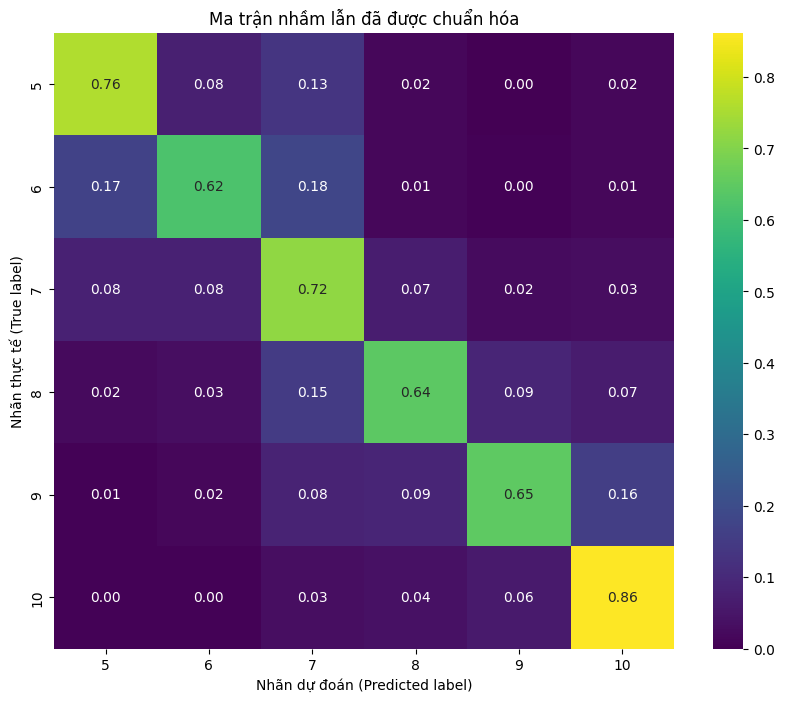

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns   # chỉ cần nếu bạn muốn dùng seaborn ở phần sau


y_pred = model_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Lấy tên các lớp dựa trên điểm rating thực tế
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='viridis',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Ma trận nhầm lẫn đã được chuẩn hóa')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()


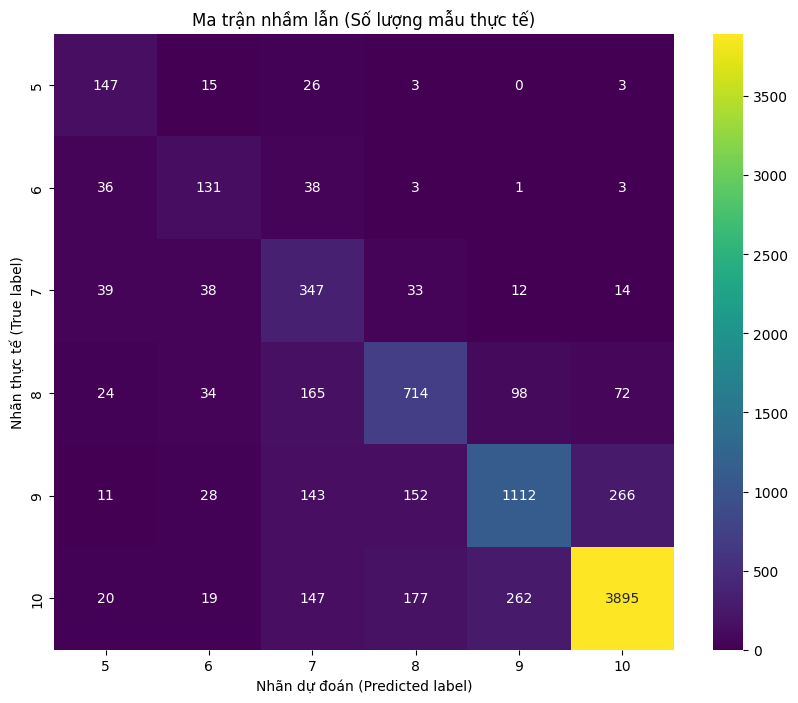

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tính ma trận nhầm lẫn (đây là dạng số lượng gốc)
cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)
# 2. Tên các lớp (từ 5 đến 10)
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))

# 3. Vẽ Heatmap với biến 'cm' gốc
sns.heatmap(
    cm,
    annot=True,      # Hiển thị số lên ô
    fmt='d',         # ĐỊNH DẠNG LÀ SỐ NGUYÊN (d = decimal/integer)
    cmap='viridis',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Ma trận nhầm lẫn (Số lượng mẫu thực tế)')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()